# 9 · A DCT upscaler that only guesses gains

Every model so far makes pixels. This one makes **gains**: it takes the DCT of small
overlapping blocks of the picture, as JPEG does, and predicts one number per coefficient -
how strongly that frequency comes through into the larger picture. Everything around the
gains is a fixed transform with no learned weights, so what learns is small, and it runs
once per block instead of once per pixel.

    LR luma ──► DCT, 8x8 blocks every 4 px ──► X ──┬─────────────────► × ──► IDCT, 16x16 blocks every 8 px ──► HR luma
                                                   └──► decide ──► g ──┘      (windowed, overlapping)
    colour: bicubic, as in notebook 7

- **The signal path is fixed, and exact.** The 16-point DCT of a block upscaled by nearest
  neighbour is the block's own 8-point DCT mirrored into four quadrants, each copy with a
  sign and a cos envelope - so the larger spectrum is never computed: it is the small one,
  copied. With every gain at 1 the model *is* nearest neighbour (checked below). A gain in
  the low quadrant says how much of an original frequency to keep - the blur of the
  downscale and the codec to undo - and a gain in the other three how much of its mirrored
  copy, which is how sharp the result is.
- **The blocks overlap by half.** Each block's IDCT is weighted by a sin² window, and the
  windows of the blocks covering a pixel add up to exactly 1, so no block edge can show.
  8 px blocks every 4 px fit the patch set's halo of 4 exactly, and the client's 320x180 step.
- **It is residual.** The *fixed* model learns one gain per coefficient, the same for every
  block: the best fixed filter of this shape, and the floor. A *deciding* model adds a
  correction that depends on the block, on top of the fixed model's gains, frozen - so it
  begins as exactly the fixed model, and all it learns is what a fixed filter cannot know.
- **The decision is as small as it can be**: two 1x1 convolutions on the block's own
  coefficients, on the block grid - a sixteenth of the LR pixels.

Steps:

1. **Data** - the patch set, and what each validation patch shows.
2. **Model** - the transforms, the checks that they are exact, and what gains chosen from
   the truth can reach: the ceiling of the design.
3. **Speed** - counted from the exported graphs, against notebook 7's model.
4. **Train** - the fixed gains, then deciding models through 8 and 32 channels on top of
   them; results overall, by content, the gain tables, and pictures.
5. **Save** - the best, and check it loads back the same.
6. **Export** - the best, and the fixed model as the cheapest tier, at the client's tile.

Needs: `00_data_preprocess.ipynb`. Writes `checkpoints/upscale_dct.pt` (the best) and each
run's training to `checkpoints/dct_runs/`.

In [2]:
"""Settings."""

import math

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset

from helpers import metrics, models, patches, speed, tiles, training, webexport
from helpers.training import DATA_DIR, DEVICE

CHECKPOINT = training.CHECKPOINT_DIR / "upscale_dct.pt"     # the best
RUN_DIR = training.CHECKPOINT_DIR / "dct_runs"              # each run's training, saved every epoch
SPEED_DIR = training.CHECKPOINT_DIR / "speed"               # graphs exported only to be counted
BEFORE = training.CHECKPOINT_DIR / "upscale_strategies.pt"  # notebook 4's luma model: the one to beat

BLOCK = 8          # LR pixels a block is wide - H.264's larger transform
STRIDE = 4         # LR pixels from one block to the next: half a block, so each pixel is in two
HIDDEN = (8, 32)   # the deciding models: channels between a block's coefficients and its gains
MAX_EPOCHS = 500   # a safety limit; each training stops once it has converged
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
SEEDS = (0, 1, 2)  # the smallest deciding model trained three times: how far luck alone moves it

STEP_WIDTH, STEP_HEIGHT = 320, 180       # LR pixels one client tile adds to the picture (notebook 5)
FRAME_WIDTH, FRAME_HEIGHT = 1920, 1080   # the whole-frame graph
ESTIMATE_ON = {"Iris Xe": "Intel Iris Xe, 96 EU (laptop iGPU)", "GTX 1650": "NVIDIA GTX 1650",
               "RTX 3060": "NVIDIA RTX 3060"}

training.seed_everything(SEEDS[0])

## 1. Data

The patch set of `00_data_preprocess.ipynb` - photos, videos and drawn desktop screens through
the stream's degradation - as notebook 8 sees it. Results are also split by what a patch
shows: a gain on a frequency is a different bet on text than on a photo.

In [3]:
manifest = training.load_manifest()
training.describe(manifest)
SCALE = manifest["scale"]
assert SCALE == 2, "the signal path below is built for x2"
train_loader, val_loader = training.loaders(DATA_DIR, manifest, BATCH_SIZE, val_batch_size=128)
trim = training.trimmer(manifest)


def content(source):
    """What a source shows: a drawn desktop screen, a photo (as a moving clip) or a video."""
    if source["dataset"] == "screens":
        return "screen"
    return "photo" if "motion" in source else "video"


by_content = {}   # what a patch shows -> the indices of its validation patches
for source in manifest["splits"]["val"]["sources"]:
    first, end = source["patches"]
    by_content.setdefault(content(source), []).extend(range(first, end))
print("val by content: " + ", ".join(f"{name} {len(indices):,}" for name, indices in by_content.items()))

device  cuda NVIDIA GeForce RTX 3090
scale   2
patch   72 px LR in (64 px + a halo of 4) -> 128 px HR out, 8 frames each
train  17140 patches from 1089 sources
val     3523 patches from 225 sources
val by content: photo 784, video 1,585, screen 1,154


## 2. Model

The signal path is four fixed convolutions and a `PixelShuffle`; nothing in it is trained.

- **`dct`**: the 8x8 DCT of every block, one direction at a time: a 1x8 convolution every
  4 px across (reading luma - BT.709 is folded into its weights), then an 8x1 every 4 px down,
  grouped by horizontal frequency. It writes each coefficient **twice**: the 16x16 spectrum
  the IDCT reads is the 8x8 one mirrored into four quadrants, so two copies of these 128
  channels side by side (a `Concat`) are all 256 of its channels, in the order the IDCT reads them.
- **`idct`**: the 16x16 IDCT, again one direction at a time, with the sin² window, the
  overlap-add and the mirrors' signs and cos envelopes folded into the weights. An output
  cell of 8x8 HR pixels is the sum of the four blocks covering it, so each direction is a
  2-tap convolution on the block grid - down, grouped by horizontal frequency, then across,
  dense - and a `PixelShuffle` lays the cells out as the sub-pixel channels every model here
  ends with.
- **`skip`**: notebook 7's bicubic, carrying colour only - bicubic of each colour minus
  bicubic of luma - since the DCT path makes all of luma.

Between them sits the only thing that learns, the gains `g`: one per channel of the 16x16
spectrum. 225 of its 256 frequencies exist - a mirrored spectrum is always zero on the row
and the column at the LR Nyquist frequency, and those 31 channels are multiplied by 0.

- **fixed**: `g` is 256 numbers, the same for every block - a fixed linear filter. Untrained,
  every gain is 1, and the model is nearest neighbour.
- **decide H**: `g = W2 · ReLU(W1 · X + b1) + fixed gains` - two 1x1 convolutions on the
  block's own coefficients, through H channels. `W2` starts at zero and its bias *is* the
  fixed model's gains, frozen: untrained, it is the fixed model exactly.

The gains are not held to 0..1: a gain over 1 undoes blur, and a negative one turns round a
mirrored copy that points the wrong way.

In [4]:
LUMA = torch.tensor(models.LUMA_709, dtype=torch.float64)


def dct_matrix(n):
    """The orthonormal DCT-II as an n x n matrix: row k is frequency k, so a block's
    coefficients are D x Dᵀ and its pixels Dᵀ X D."""
    k = torch.arange(n, dtype=torch.float64)[:, None]
    i = torch.arange(n, dtype=torch.float64)[None]
    matrix = math.sqrt(2 / n) * torch.cos(math.pi * (2 * i + 1) * k / (2 * n))
    matrix[0] /= math.sqrt(2)
    return matrix


def spectrum_layout(n=BLOCK):
    """Where each of the 256 spectrum channels sits in the 16x16 spectrum.

    Along one axis, index q * n + i is LR frequency i in quadrant q: frequency k = i in the
    near quadrant, 2n - i in the far one (2n, where i = 0, is no frequency). Channel
    (qv * n + v) * 2n + qu * n + u is LR coefficient (u, v) in quadrant (qu, qv).

    Returns k (per axis index), U and V (per channel: its vertical and horizontal frequency)
    and the factor that turns the LR coefficient into that coefficient of the nearest-
    neighbour upscaled block: √2 cos(πk / 4n) per axis, negative past the middle, 0 at 2n.
    """
    m = 2 * n
    q, i = torch.meshgrid(torch.arange(2), torch.arange(n), indexing="ij")
    k = torch.where(q == 0, i, m - i).flatten()
    factor = torch.where(k < n, 1.0, -1.0).double() * math.sqrt(2) * torch.cos(math.pi * k.double() / (2 * m))
    factor[k == m] = 0
    return k, k.repeat(m), k.repeat_interleave(m), factor.repeat_interleave(m) * factor.repeat(m)


def frozen(conv, weight):
    """`conv` with these weights, never trained."""
    with torch.no_grad():
        conv.weight.copy_(weight.reshape(conv.weight.shape))
    conv.weight.requires_grad_(False)
    return conv


class DctUpscaler(models.Upscaler):
    """Bicubic colour, and luma made by gains on the DCT of overlapping blocks.

    `hidden=0` is the fixed model: one learned gain per spectrum channel. `hidden=H` decides
    the gains of each block from its coefficients, through H channels; `start_from(fixed)`
    puts a fixed model's gains under it, frozen.
    """

    def __init__(self, hidden=0, block=BLOCK, stride=STRIDE, scale=2):
        super().__init__(scale, skip=5)
        assert block == 2 * stride, "the windows add up to 1 only at half a block's overlap"
        n, m, cell = block, 2 * block, stride * scale   # LR block, HR block, HR pixels from block to block
        self.hidden, self.block, self.stride = hidden, block, stride
        self.halo = max(block - stride, self.skip_size // 2)   # the first block starts 4 px before the core

        # colour: bicubic of each colour minus bicubic of luma (the DCT path adds luma back)
        phases = models.bicubic_kernel(scale, self.skip_size).double()
        carry = torch.eye(3, dtype=torch.float64) - LUMA[None]
        frozen(self.skip.conv, torch.einsum("cj,pyx->cpjyx", carry, phases).float())

        d = dct_matrix(n)
        window = torch.sin(math.pi * (torch.arange(m, dtype=torch.float64) + 0.5) / m) ** 2
        basis = dct_matrix(m) * window   # row k: frequency k over a 16 px block, windowed
        k, U, V, factor = spectrum_layout(n)

        # dct: across (luma -> horizontal frequency v), then down, grouped by v; output channel
        # (v * 2 + qu) * n + u is DCT row u, once for each quadrant qu
        across = torch.einsum("c,vx->vcx", LUMA, d)
        down = d.repeat(2 * n, 1)
        self.dct = nn.Sequential(
            frozen(nn.Conv2d(3, n, (1, n), stride=(1, stride), bias=False), across.float()),
            frozen(nn.Conv2d(n, 2 * n * n, (n, 1), stride=(stride, 1), groups=n, bias=False), down.float()))

        # idct: down, grouped by horizontal frequency, then across, dense. Output cell i is the
        # second half of block i - 1 (tap 0) and the first half of block i (tap 1).
        half = torch.arange(cell)
        Uk = U.clamp(max=m - 1)   # k = 2n is no frequency: its factor is 0 anyway
        columns = torch.stack([basis[Uk][:, half + cell], basis[Uk][:, half]], dim=-1) * factor[:, None, None]
        columns = columns.reshape(m, m, cell, 2).permute(0, 2, 1, 3)   # (V group, y, U in the group, tap)
        rows = torch.zeros(scale * scale * stride * stride, m * cell, 1, 2, dtype=torch.float64)
        for group in range(m):   # horizontal frequency k[group]
            if k[group] == m:
                continue
            for y in range(cell):
                for x in range(cell):
                    (by, dy), (bx, dx) = divmod(y, scale), divmod(x, scale)
                    out = ((dy * scale + dx) * stride + by) * stride + bx   # PixelShuffle(stride)'s order
                    rows[out, group * cell + y, 0] = torch.stack([basis[k[group], x + cell], basis[k[group], x]])
        self.idct = nn.Sequential(
            frozen(nn.Conv2d(m * m, m * cell, (2, 1), padding=(1, 0), groups=m, bias=False), columns.float()),
            frozen(nn.Conv2d(m * cell, scale * scale * stride * stride, (1, 2), padding=(0, 1), bias=False),
                   rows.float()),
            nn.PixelShuffle(stride))

        if hidden == 0:
            self.base = nn.Parameter(torch.ones(1, m * m, 1, 1))   # untrained: nearest neighbour
        else:
            self.decide = nn.Sequential(nn.Conv2d(2 * n * n, hidden, 1), nn.ReLU(inplace=True),
                                        models.zero_start(nn.Conv2d(hidden, m * m, 1)))
            self.decide[2].bias.data.fill_(1.0)
            self.decide[2].bias.requires_grad_(False)   # the fixed gains, set by start_from

    @torch.no_grad()
    def start_from(self, fixed):
        """Put a fixed model's gains under this one, frozen: untrained, it is that model."""
        self.decide[2].bias.copy_(fixed.base.flatten())
        return self

    def gains(self, coefficients):
        return self.base if self.hidden == 0 else self.decide(coefficients)

    def residual(self, x):
        coefficients = self.dct(x)
        spectrum = torch.cat([coefficients, coefficients], dim=1)
        luma = self.idct(spectrum * self.gains(coefficients))
        return torch.cat([luma, luma, luma], dim=1)   # on every colour: Y moves, Cb and Cr do not

In [5]:
"""Checks: untrained, luma is nearest neighbour and colour bicubic, and a deciding model is its fixed model."""

models.check_skip_is_bicubic(SCALE)
lr_probe = next(iter(val_loader))[0][:8].to(DEVICE)
yuv = metrics.rgb_to_yuv

with torch.no_grad(), training.full_precision():
    untrained = DctUpscaler().to(DEVICE)
    assert untrained.halo <= manifest["halo"], "the model reaches further than the patches' halo"
    out = yuv(trim(untrained(lr_probe)))
    nearest = yuv(trim(F.interpolate(lr_probe, scale_factor=SCALE, mode="nearest")))
    bicubic = yuv(trim(models.bicubic(lr_probe, SCALE)))
    gaps = {"luma against nearest": (out[:, :1] - nearest[:, :1]).abs().max().item(),
            "colour against bicubic": (out[:, 1:] - bicubic[:, 1:]).abs().max().item()}
    # a deciding model, untrained, is the fixed model it starts from - whatever that one's gains
    some_fixed = DctUpscaler().to(DEVICE)
    some_fixed.base.normal_(1, 0.3)
    for hidden in HIDDEN:
        deciding = DctUpscaler(hidden).to(DEVICE).start_from(some_fixed)
        gaps[f"decide {hidden} against its fixed model"] = (deciding(lr_probe) - some_fixed(lr_probe)).abs().max().item()
for name, gap in gaps.items():
    assert gap < 1e-5, f"{name}: {gap:.1e}"
print("exact, to float32 rounding: " + ", ".join(f"{name} {gap:.0e}" for name, gap in gaps.items()))
for hidden in (0, *HIDDEN):
    name = "fixed" if hidden == 0 else f"decide {hidden}"
    print(f"{name:<10}{models.count_parameters(DctUpscaler(hidden), True):7,} learned parameters")

exact, to float32 rounding: luma against nearest 8e-07, colour against bicubic 2e-07, decide 8 against its fixed model 0e+00, decide 32 against its fixed model 0e+00
fixed         256 learned parameters
decide 8    3,080 learned parameters
decide 32  12,320 learned parameters


### What gains can reach

Before training anything: the model with each block's gains chosen *from the truth*.

- **any gains, from the truth**: each block's spectrum becomes exactly the truth's, however
  large or negative a gain that takes. Only the row and the column at the LR Nyquist
  frequency are missing, since no mirrored spectrum holds them. This is the ceiling of the
  design at this block size: what is lost here, no decision can win back.
- **gains ≥ 0, from the truth**: the same, except that a gain cannot turn a sign round -
  where the truth and the mirror disagree, the best it can do is 0. How far this falls below
  the ceiling says how often a mirrored copy points the wrong way.
- **nearest** (every gain 1) and **bicubic**: the fixed filters there are to start from.

Neither of the first two is reachable - they read the answer. Every row here is scored on
the inner 112 px of the 128 px core: the blocks at a patch's edge reach past its target,
where there is no truth to choose gains from.

In [6]:
INNER = 8   # HR pixels cut from each side of the core, where the edge blocks reach past the target


def truth_weights(n=BLOCK):
    """A convolution that reads a 16x16 HR block into the 256 spectrum channels, divided by
    the nearest-neighbour factor: the spectrum that gives the block back through `idct`."""
    m = 2 * n
    k, U, V, factor = spectrum_layout(n)
    D = dct_matrix(m)
    weight = torch.zeros(m * m, 1, m, m, dtype=torch.float64)
    there = factor != 0
    weight[there, 0] = D[U[there], :, None] * D[V[there], None, :] / factor[there, None, None]
    return weight.float().to(DEVICE)


TRUTH = truth_weights()


@torch.no_grad()
def from_truth(model, lr, hr, keep_sign):
    """The model's output with every block's gains chosen from the truth `hr` (the core):
    the spectrum that gives `hr` back - with `keep_sign`, 0 wherever that needs a negative gain."""
    pad = manifest["halo"] * SCALE   # the first block starts this far before the core
    truth = F.conv2d(F.pad(yuv(hr)[:, :1], [pad] * 4, mode="replicate"), TRUTH, stride=model.stride * SCALE)
    if keep_sign:
        coefficients = model.dct(lr)
        mirrored = torch.cat([coefficients, coefficients], dim=1)
        truth = torch.where(truth * mirrored > 0, truth, torch.zeros_like(truth))
    luma = model.idct(truth)
    return model.shuffle(model.skip(lr) + torch.cat([luma, luma, luma], dim=1))


@torch.no_grad()
def score_inner(make):
    """`metrics.report` of `make(lr, hr)` over the validation set, on the inner 112 px of each core."""
    totals, count = {}, 0
    for lr, hr in val_loader:
        lr, hr = lr.to(DEVICE), hr.to(DEVICE)
        scores = metrics.report(patches.trim(trim(make(lr, hr)), INNER), patches.trim(hr, INNER))
        for key, value in scores.items():
            totals[key] = totals.get(key, 0.0) + value * len(hr)
        count += len(hr)
    return {key: value / count for key, value in totals.items()}


untrained = DctUpscaler().to(DEVICE).eval()
ceiling = {"bicubic": score_inner(lambda lr, hr: models.bicubic(lr, SCALE)),
           "nearest (every gain 1)": score_inner(lambda lr, hr: untrained(lr)),
           "gains >= 0, from the truth": score_inner(lambda lr, hr: from_truth(untrained, lr, hr, keep_sign=True)),
           "any gains, from the truth": score_inner(lambda lr, hr: from_truth(untrained, lr, hr, keep_sign=False))}
metrics.print_table(ceiling)

                                wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic                         34.68    33.74    51.35    52.17     32.53   0.9051
nearest (every gain 1)          32.88    31.86    51.36    52.18     31.00   0.8889
gains >= 0, from the truth      39.05    38.86    51.42    52.21     35.60   0.9550
any gains, from the truth       41.87    42.89    51.44    52.23     37.42   0.9743


## 3. Speed

Counted the way notebooks 3, 4 and 8 count: operations and memory traffic in the exported
ONNX graph at the client's tile, per LR pixel, and the roofline estimate for a 1080p frame.
The estimate takes the share of its peak this computer's GPU reaches on notebook 7's model in
torch, for every model - a graph of a few small operators may well reach less, so the
milliseconds measured here are printed beside it. The graphs are untrained: the work does not
depend on the weights.

The graphs are `Conv`, `Concat`, `DepthToSpace`, `Relu`, `Add` - and one **`Mul`**, the gains
times the coefficients, which is the idea itself and the one operator outside the budget the
browser has been measured on.

In [7]:
plan = tiles.plan_tiling((FRAME_WIDTH, FRAME_HEIGHT), scale=SCALE, halo=manifest["halo"])
tile_shape = plan["input"][2:]   # (height, width) of one tile, halo included
assert all(side % STRIDE == 0 for side in tile_shape), "a tile must be a whole number of block steps"
frame_lr = torch.rand(1, 3, FRAME_HEIGHT // SCALE, FRAME_WIDTH // SCALE, device=DEVICE)


def frame_work(cost, pixels, runs):
    """Operations and bytes for `pixels` LR pixels, computed in `runs` runs of the graph."""
    return {"operations": pixels * cost["ops"], "bytes": pixels * cost["bytes"] + runs * cost["weight_bytes"]}


def cost(model, name):
    """Operations and bytes per LR pixel of a model's graph at the client's tile, and the
    milliseconds of a 1080p frame through it in torch on this computer."""
    model = model.to(DEVICE).eval()
    graph = webexport.export(model, f"speed_check_{name}.onnx", tile_shape, halo=model.halo, models_dir=SPEED_DIR)
    work = webexport.count_work(graph["path"])
    with torch.no_grad():
        measured_ms = speed.time_ms(lambda: model(frame_lr), seconds=1.0)
    return {"ops": work["operations"] / work["input_pixels"], "bytes": work["activation_bytes"] / work["input_pixels"],
            "weight_bytes": work["weight_bytes"], "measured_ms": measured_ms, "graph": graph}


costs = {"notebook 7": cost(models.LumaUpscaler((24,), 2, 3, scale=SCALE), "luma_24x2"),
         "fixed": cost(DctUpscaler(), "dct_fixed"),
         **{f"decide {h}": cost(DctUpscaler(h), f"dct_h{h}") for h in HIDDEN}}

# calibrate on notebook 7's model, run as one whole frame
reference = costs["notebook 7"]
whole_frame = frame_work(reference, frame_lr.shape[2] * frame_lr.shape[3], runs=1)
efficiency = (speed.roofline_ms(whole_frame, *speed.HARDWARE[speed.THIS_GPU])[0] / reference["measured_ms"]
              if DEVICE.type == "cuda" else 1.0)
print(f"estimates at {efficiency:.0%} of each device's peak (notebook 7's model here)\n")
print(f"{'':<12}{'ops / LR px':>12}{'bytes / LR px':>15}{'here, ms':>10}"
      + "".join(f"{short + ', ms':>14}" for short in ESTIMATE_ON))
tiled_pixels = plan["runs"] * tile_shape[0] * tile_shape[1]
for name, c in costs.items():
    estimates = [speed.roofline_ms(frame_work(c, tiled_pixels, plan["runs"]), *speed.HARDWARE[device])
                 for device in ESTIMATE_ON.values()]
    print(f"{name:<12}{c['ops']:12,.0f}{c['bytes']:15,.0f}{c['measured_ms']:10.2f}"
          + "".join(f"{ms / efficiency:7.1f} ({limit[0]})".rjust(14) for ms, limit in estimates))
print("\n(c) compute-bound, (m) memory-bound")
for c in costs.values():
    print(webexport.summary_line(c["graph"]))

estimates at 43% of each device's peak (notebook 7's model here)

             ops / LR px  bytes / LR px  here, ms   Iris Xe, ms  GTX 1650, ms  RTX 3060, ms
notebook 7        28,120          2,536      3.23      47.6 (m)      25.3 (m)       9.0 (m)
fixed              4,600            875      1.23      16.5 (m)       8.7 (m)       3.1 (m)
decide 8           4,987          1,038      1.36      19.5 (m)      10.4 (m)       3.7 (m)
decide 32          6,104          1,061      1.38      20.0 (m)      10.6 (m)       3.8 (m)

(c) compute-bound, (m) memory-bound
speed_check_luma_24x2.onnx                             57.6 KB   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3
speed_check_dct_fixed.onnx                             91.1 KB   Addx1, Concatx2, Convx5, DepthToSpacex2, Mulx1   OUTSIDE BUDGET: Mul
speed_check_dct_h8.onnx                               103.8 KB   Addx1, Concatx2, Convx7, DepthToSpacex2, Mulx1, Relux1   OUTSIDE BUDGET: Mul
speed_check_dct_h32.onnx                        

## 4. Train

The recipe of notebooks 2 to 8: Adam from 1e-3, batch 32, `metrics.ssim_l1_loss`, the epoch
with the best luma SSIM kept, each run trained until it has converged.

The fixed model first. Then each deciding model **starts from it**: the fixed gains are its
frozen bias and its correction starts at zero, so its untrained score is the fixed model's,
and whatever it gains over that is the decision's. `decide 8` is trained at three seeds -
their spread is what luck alone moves a score - and `decide 32` at one.

Each run saves its training to `checkpoints/dct_runs/` after every epoch: run the cell again
after an interruption and it carries on; finished runs just load. The deciding runs start
from the fixed one, so retraining that means deleting them too.

In [8]:
def train(hidden=0, seed=0, fixed=None):
    """Train a fresh model, or load its saved training. Returns it at its best epoch, its
    history and its best epoch."""
    torch.manual_seed(seed)
    model = DctUpscaler(hidden).to(DEVICE)
    if fixed is not None:
        model.start_from(fixed)
    torch.manual_seed(seed)   # the same batches in the same order, whatever the model
    run = ("fixed" if hidden == 0 else f"decide{hidden}") + f"_seed{seed}"
    history, best = training.train(model, train_loader, val_loader, trim, MAX_EPOCHS, learning_rate=LEARNING_RATE,
                                   loss_fn=metrics.ssim_l1_loss, select="ssim", checkpoint=RUN_DIR / f"{run}.pt",
                                   verbose=0)
    print(f"{run:<16} best epoch {best['epoch']:3} of {len(history):3}, ssim-y {best['score']:.4f}")
    return model, history, best


trained, histories, bests = {}, {}, {}
trained["fixed"], histories["fixed"], bests["fixed"] = train()
for seed in SEEDS:
    name = f"decide {HIDDEN[0]}, seed {seed}"
    trained[name], histories[name], bests[name] = train(HIDDEN[0], seed, fixed=trained["fixed"])
for hidden in HIDDEN[1:]:
    name = f"decide {hidden}"
    trained[name], histories[name], bests[name] = train(hidden, fixed=trained["fixed"])

# notebook 4's winner, the same body as notebook 7's: the model to beat
before = training.load_checkpoint(BEFORE)
trained["notebook 4's model"] = getattr(models, before["architecture"])(scale=SCALE, **before["arguments"]).to(DEVICE)
trained["notebook 4's model"].load_state_dict(before["state_dict"])
print(f"notebook 4's model: its {before['strategy']}, loaded")

fixed_seed0      best epoch  14 of  56, ssim-y 0.9107
decide8_seed0    best epoch  60 of  96, ssim-y 0.9151
decide8_seed1    best epoch  34 of  70, ssim-y 0.9143
decide8_seed2    best epoch  69 of  93, ssim-y 0.9147
decide32_seed0   best epoch  39 of  81, ssim-y 0.9172
notebook 4's model: its luma 24 + 2 blocks, loaded


### The result

Every model on the whole validation set - the 128 px cores, as every notebook scores - with
the operations it takes per LR pixel. **better** / **worse** means a gap wider than the
spread of `decide 8`'s three seeds; **luck** means this set cannot tell the two apart.

The questions, in order: is the best fixed filter of this shape above bicubic; what is the
decision worth over it; does a wider decision add more; and how far is notebook 4's model.

In [9]:
BASELINES = {"bicubic": models.Resize(SCALE), "nearest": models.Resize(SCALE, "nearest")}


def score(name, indices=None):
    """`metrics.report` of one model (or baseline) on the validation patches `indices` (None: all)."""
    dataset = val_loader.dataset if indices is None else Subset(val_loader.dataset, indices)
    model = BASELINES[name] if name in BASELINES else trained[name]
    return training.evaluate(model.to(DEVICE), DataLoader(dataset, batch_size=128), trim)


def ops(name, scores):
    """The last column: operations per LR pixel of the model's graph."""
    if name in BASELINES:
        return ""
    graph = "notebook 7" if name == "notebook 4's model" else name.split(",")[0]   # a seed costs what its model does
    return f"{costs[graph]['ops']:12,.0f}"


def compare(a, b, label):
    word = "luck" if abs(a - b) <= spread else ("better" if a > b else "worse")
    print(f"{label:<46}{a - b:+.4f} ssim-y  {word}")


results = {name: score(name) for name in [*BASELINES, *trained]}
seeds = [results[f"decide {HIDDEN[0]}, seed {seed}"]["ssim"] for seed in SEEDS]
spread = max(seeds) - min(seeds)
print(f"decide {HIDDEN[0]} at {len(SEEDS)} seeds: {spread:.4f} ssim-y apart. Last column: operations per LR pixel.")
metrics.print_table(results, extra=ops)

dct_names = [name for name in trained if name.startswith(("fixed", "decide"))]
best_dct = max(dct_names, key=lambda name: results[name]["ssim"])
print()
compare(results["fixed"]["ssim"], results["bicubic"]["ssim"], "fixed over bicubic")
compare(float(np.mean(seeds)), results["fixed"]["ssim"], f"decide {HIDDEN[0]} (mean of its seeds) over fixed")
for hidden in HIDDEN[1:]:
    compare(results[f"decide {hidden}"]["ssim"], float(np.mean(seeds)), f"decide {hidden} over decide {HIDDEN[0]}")
compare(results["notebook 4's model"]["ssim"], results[best_dct]["ssim"], f"notebook 4's model over {best_dct}")

decide 8 at 3 seeds: 0.0008 ssim-y apart. Last column: operations per LR pixel.
                        wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic                 34.14    33.18    50.67    51.46     32.02   0.9049
nearest                 32.39    31.36    50.33    51.12     30.52   0.8887
fixed                   34.40    33.45    50.67    51.46     32.24   0.9107       4,600
decide 8, seed 0        34.43    33.48    50.67    51.46     32.23   0.9151       4,987
decide 8, seed 1        34.36    33.40    50.66    51.45     32.18   0.9143       4,987
decide 8, seed 2        34.40    33.45    50.67    51.46     32.20   0.9147       4,987
decide 32               34.39    33.45    50.66    51.45     32.19   0.9172       6,104
notebook 4's model      35.33    34.45    50.70    51.49     32.96   0.9292      28,120

fixed over bicubic                            +0.0057 ssim-y  better
decide 8 (mean of its seeds) over fixed       +0.0040 ssim-y  better
decide 32 over decide 8  

### By content

The gain over bicubic on screens, photos and video apart: luma SSIM, and luma PSNR in dB.
What the decision is worth on screens, where a sharp edge has to land in the right place,
against photos and video.

In [10]:
SHOW = ["nearest", "fixed", f"decide {HIDDEN[0]}, seed 0", *[f"decide {h}" for h in HIDDEN[1:]], "notebook 4's model"]
print(f"{'':<8}{'patches':>8}{'bicubic ssim-y':>16}" + "".join(f"{name:>22}" for name in SHOW))
for value, indices in by_content.items():
    base = score("bicubic", indices)
    row = f"{value:<8}{len(indices):8,}{base['ssim']:16.4f}"
    for name in SHOW:
        scores = score(name, indices)
        row += f"{scores['ssim'] - base['ssim']:+.4f} / {scores['y'] - base['y']:+.2f}".rjust(22)
    print(row)

         patches  bicubic ssim-y               nearest                 fixed      decide 8, seed 0             decide 32    notebook 4's model
photo        784          0.8359       -0.0256 / -1.61       +0.0085 / +0.24       +0.0119 / +0.18       +0.0129 / +0.14       +0.0217 / +0.74
video      1,585          0.9535       -0.0169 / -2.77       +0.0002 / +0.21       +0.0033 / +0.21       +0.0044 / +0.20       +0.0122 / +1.20
screen     1,154          0.8851       -0.0090 / -0.66       +0.0114 / +0.38       +0.0184 / +0.51       +0.0227 / +0.45       +0.0425 / +1.75


### The gain tables

The fixed model's gains laid out as the 16x16 spectrum - this model's "quantization table",
read the other way round: how strongly each frequency of the nearest-neighbour block comes
through. Rows are vertical frequency, columns horizontal; the blank row and column are the LR
Nyquist frequency, so the top-left quadrant is what the LR picture had and the other three
are mirrored copies. Beside it, for the best deciding model over the validation blocks: the
mean gain, and how far the decision moves each gain (its standard deviation) - the
frequencies that depend on content.

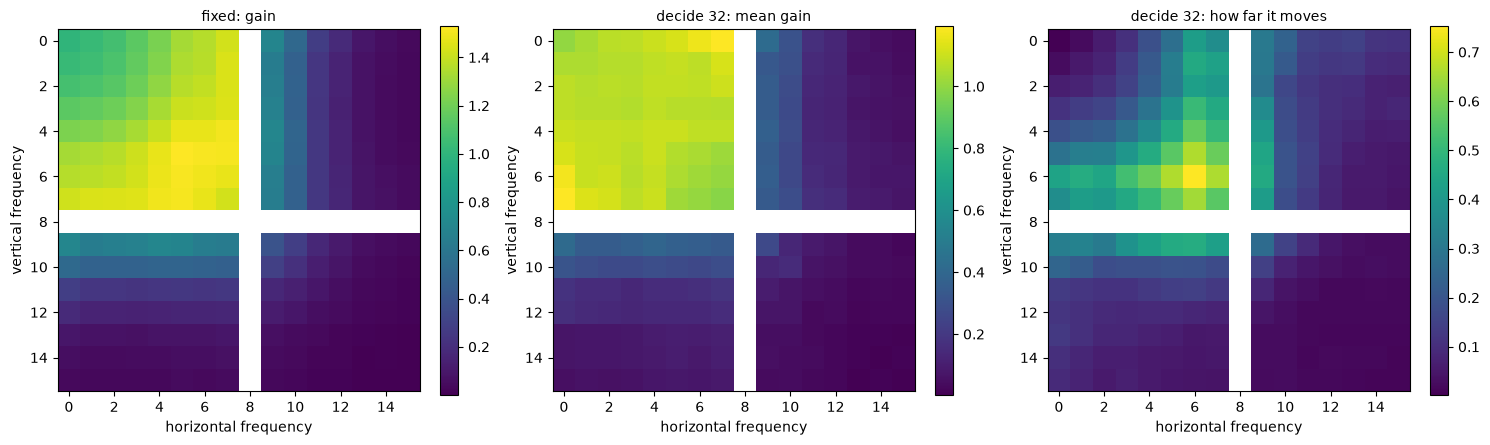

In [11]:
def gain_table(values):
    """256 gains in channel order -> the 16x16 spectrum, NaN where there is no frequency."""
    k, U, V, factor = spectrum_layout()
    table = torch.full((2 * BLOCK, 2 * BLOCK), float("nan"))
    there = factor != 0
    table[U[there], V[there]] = values.detach().flatten().float().cpu()[there]
    return table.numpy()


best_deciding = max((name for name in dct_names if name.startswith("decide")), key=lambda name: results[name]["ssim"])
deciding = trained[best_deciding].eval()
total, squares, count = 0, 0, 0
with torch.no_grad():
    for lr, _ in val_loader:
        g = deciding.gains(deciding.dct(lr.to(DEVICE)))   # (N, 256, blocks down, blocks across)
        total, squares, count = total + g.sum(dim=(0, 2, 3)), squares + (g * g).sum(dim=(0, 2, 3)), count + g[:, 0].numel()
mean = total / count
panels = {"fixed: gain": gain_table(trained["fixed"].base),
          f"{best_deciding}: mean gain": gain_table(mean),
          f"{best_deciding}: how far it moves": gain_table((squares / count - mean ** 2).clamp_min(0).sqrt())}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, (title, table) in zip(axes, panels.items()):
    image = ax.imshow(table, cmap="viridis")
    fig.colorbar(image, ax=ax, fraction=0.046)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("horizontal frequency")
    ax.set_ylabel("vertical frequency")
fig.tight_layout()
plt.show()

### What it looks like

Four held-out screens: bicubic, the best DCT model, notebook 4's model and the target.

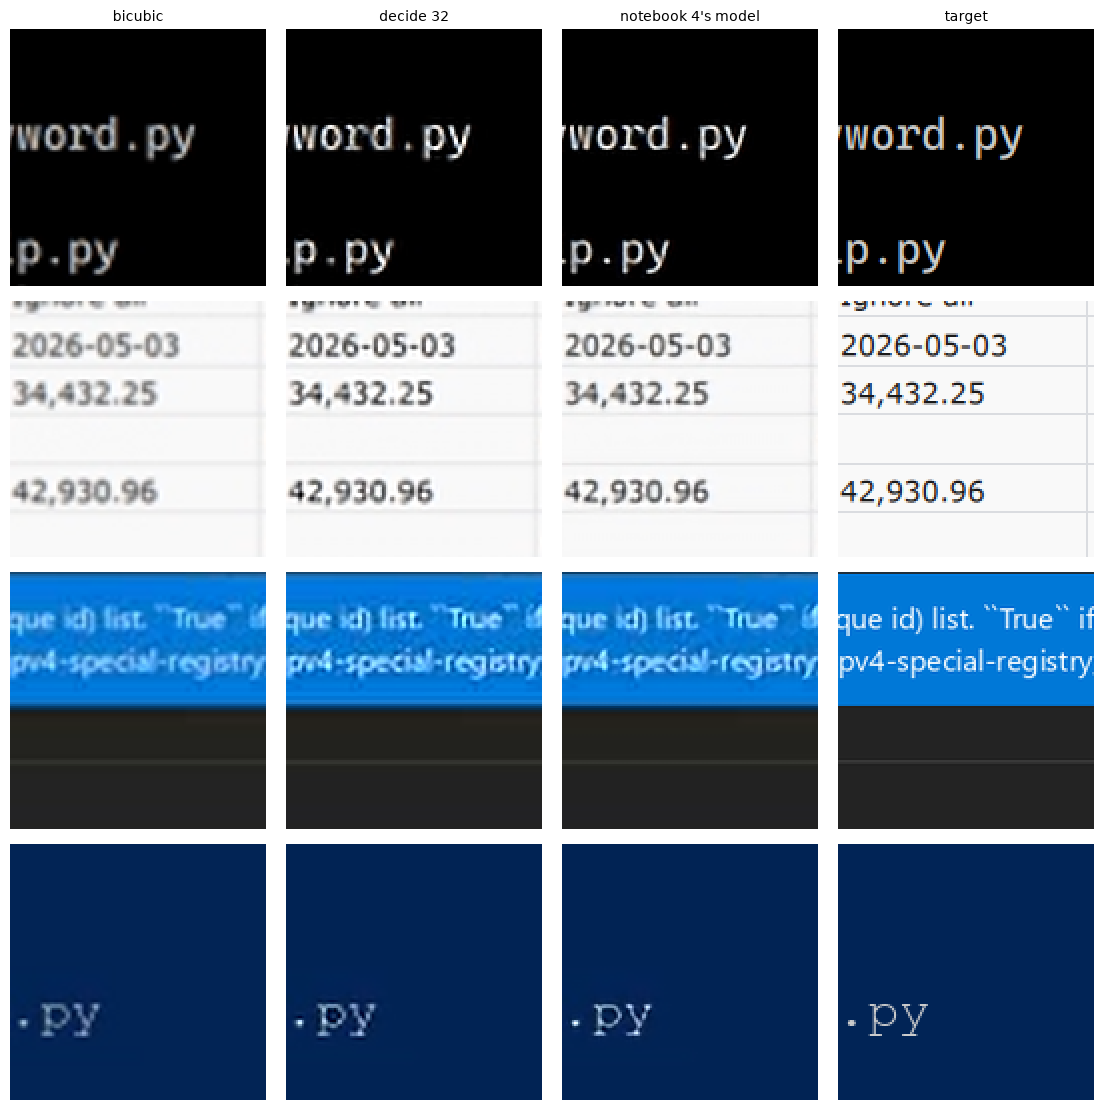

In [12]:
shown = by_content["screen"][::max(1, len(by_content["screen"]) // 4)][:4]
lr = torch.stack([val_loader.dataset[i][0] for i in shown]).to(DEVICE)
hr = torch.stack([val_loader.dataset[i][1] for i in shown])
with torch.no_grad():
    training.show_patches({"bicubic": trim(models.bicubic(lr, SCALE)),
                           best_dct: trim(trained[best_dct].eval()(lr)),
                           "notebook 4's model": trim(trained["notebook 4's model"].eval()(lr)),
                           "target": hr})

## 5. Save and reload

The best DCT model by luma SSIM is saved with everything needed to rebuild it. We load it
into a fresh model and check it computes the same thing.

In [13]:
best = trained[best_dct]
training.save_checkpoint(CHECKPOINT, best, architecture="DctUpscaler",
                         arguments={"hidden": best.hidden, "block": best.block, "stride": best.stride},
                         scale=SCALE, halo=best.halo, loss="ssim_l1_loss", select="ssim",
                         epochs=len(histories[best_dct]), best_epoch=bests[best_dct]["epoch"],
                         val=results[best_dct], val_bicubic=results["bicubic"], seed_spread=spread,
                         degradation=manifest["degradation"])

# rebuild it from the file alone, the way a later notebook would
checkpoint = training.load_checkpoint(CHECKPOINT)
loaded = DctUpscaler(scale=checkpoint["scale"], **checkpoint["arguments"]).to(DEVICE)
loaded.load_state_dict(checkpoint["state_dict"])
training.assert_same_model(best, loaded)
print("reloaded model is identical")

saved /home/henrik/desktop-streamer-ai/src/upscale/checkpoints/upscale_dct.pt (146 KB)
reloaded model is identical


## 6. Export for the browser

At the client's tile (a 320x180 step): float32 and float16, and float16 as a whole 1080p
frame - the best model, and the fixed model if it is not the best: the cheapest tier there is.

In [14]:
def input_shape(step_height, step_width, halo):
    """The model input for a step: the step plus the halo on every side, as (height, width)."""
    return (step_height + 2 * halo, step_width + 2 * halo)


def check_and_time(info, module, shape, dtype, tolerance):
    """Check a written graph against the torch module, time it on the CPU, print one line."""
    webexport.check_graph(info["path"], module, np.random.rand(1, 3, *shape).astype(np.float32), dtype, tolerance)
    ms = webexport.time_graph(info["path"], shape, dtype)
    webexport.annotate(info, cpu_ms=round(ms, 2))
    print(webexport.summary_line(info, ms))


tile_name = f"tile{STEP_WIDTH}x{STEP_HEIGHT}"
for module in {best_dct: best, "fixed": trained["fixed"]}.values():   # one entry if the best is fixed
    name = "dct_fixed" if module.hidden == 0 else f"dct_h{module.hidden}"
    tile_shape = input_shape(STEP_HEIGHT, STEP_WIDTH, module.halo)
    frame_shape = input_shape(FRAME_HEIGHT // SCALE, FRAME_WIDTH // SCALE, module.halo)

    fp32 = webexport.export(module, f"upscale_{name}_{tile_name}.onnx", tile_shape, label=f"{name} fp32",
                            halo=module.halo)
    check_and_time(fp32, module, tile_shape, np.float32, tolerance=2e-3)

    fp16 = webexport.to_float16(fp32, f"upscale_{name}_fp16_{tile_name}.onnx")
    webexport.write_metadata(fp16["path"], {"label": f"{name} fp16"})
    check_and_time(fp16, module, tile_shape, np.float16, tolerance=4e-3)

    frame = webexport.to_frame(fp16, f"upscale_{name}_fp16_{tile_name}_frame.onnx", FRAME_WIDTH, FRAME_HEIGHT)
    check_and_time(frame, module, frame_shape, np.float16, tolerance=4e-3)
print("compare in a browser: uv run src/upscale/benchmark/main.py")

upscale_dct_h32_tile320x180.onnx                      139.9 KB    1.98 ms   Addx1, Concatx2, Convx7, DepthToSpacex2, Mulx1, Relux1   OUTSIDE BUDGET: Mul
upscale_dct_h32_fp16_tile320x180.onnx                  71.9 KB    1.95 ms   Addx1, Concatx2, Convx7, DepthToSpacex2, Mulx1, Relux1   OUTSIDE BUDGET: Mul
upscale_dct_h32_fp16_tile320x180_frame.onnx            71.9 KB   32.97 ms   Addx1, Concatx2, Convx7, DepthToSpacex2, Mulx1, Relux1   OUTSIDE BUDGET: Mul
upscale_dct_fixed_tile320x180.onnx                     91.1 KB    1.83 ms   Addx1, Concatx2, Convx5, DepthToSpacex2, Mulx1   OUTSIDE BUDGET: Mul
upscale_dct_fixed_fp16_tile320x180.onnx                47.0 KB    1.88 ms   Addx1, Concatx2, Convx5, DepthToSpacex2, Mulx1   OUTSIDE BUDGET: Mul
upscale_dct_fixed_fp16_tile320x180_frame.onnx          47.0 KB   24.85 ms   Addx1, Concatx2, Convx5, DepthToSpacex2, Mulx1   OUTSIDE BUDGET: Mul
compare in a browser: uv run src/upscale/benchmark/main.py
